In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path

sys.path.append(str(Path("..").resolve()))

In [116]:
from scripts_.stitching_vk_data import plot_stitched_height_image_from_vk #, plot_stitched_height_image_from_vk_2
from scripts_.tilt_correction import baseplane_filter
from scripts_.plot_vk_data import plot_vk4_height, plot_vk4_reflected_light
from scripts_.load_vk_data import parse_vk6_file, parse_vk4_file
from scripts_.preprocess_vk_data import crop_Vk4File_map
from scripts_.feature_enhancement import feature_enhancement_proceedings, feature_enhancement_single_gaussian_clip, feature_enhancement_double_gaussian_clip, feature_enhancement_triple_gaussian_clip, feature_enhancement_single_gaussian_median_clip, feature_enhancement_double_gaussian_median_clip, feature_enhancement_median_clip_high, feature_enhancement_cut_elevations_and_holes, feature_enhancement_morphological
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter

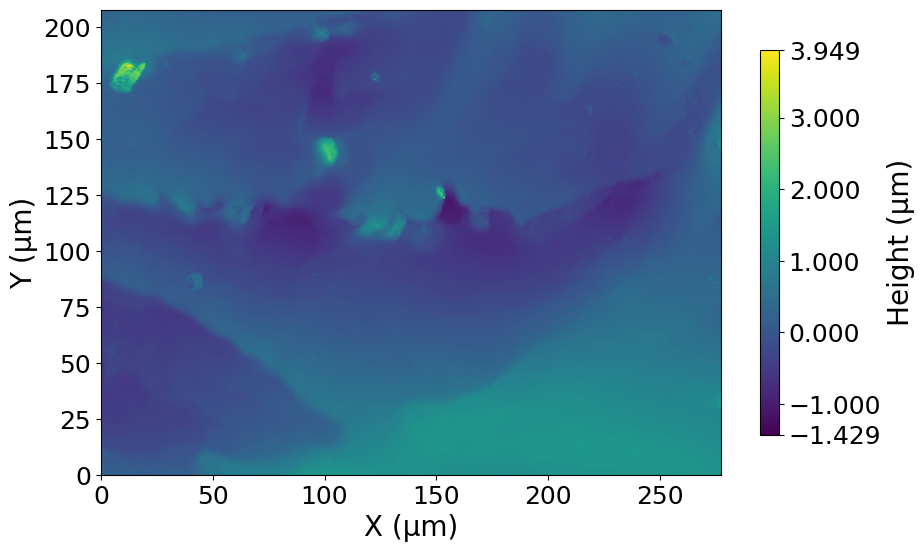

In [127]:
file_name = Path("../raw_data_vk/Sample 3 Milan full/Stitched 50x small area/20260617173422_Y1_X1.vk4")

with open(file_name, 'rb') as f:
    data_1_vk4 = parse_vk4_file(f)


data_1_vk4_tiltcorr = baseplane_filter(data_1_vk4, 60)

ax = plot_vk4_height(data_1_vk4_tiltcorr, data_type='baseplane_subtracted')

**Current status**

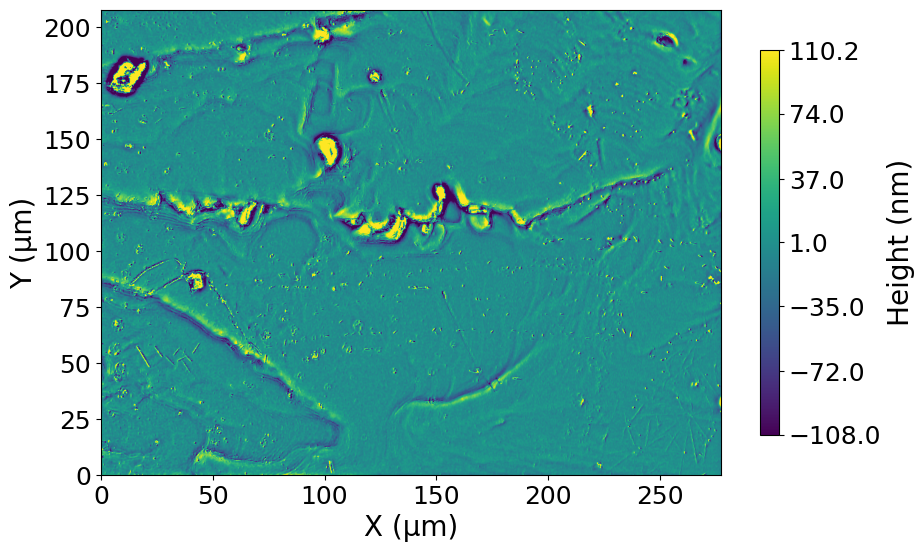

In [47]:
data_1_vk4_enhanced = feature_enhancement_proceedings(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Histograms of height data**

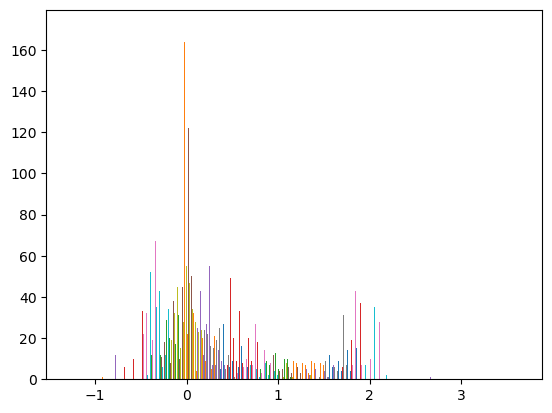

In [ ]:
# cell takes 3 min  
data_processed = data_1_vk4_tiltcorr['baseplane_subtracted']
plt.hist(data_processed, bins=100)
plt.show()

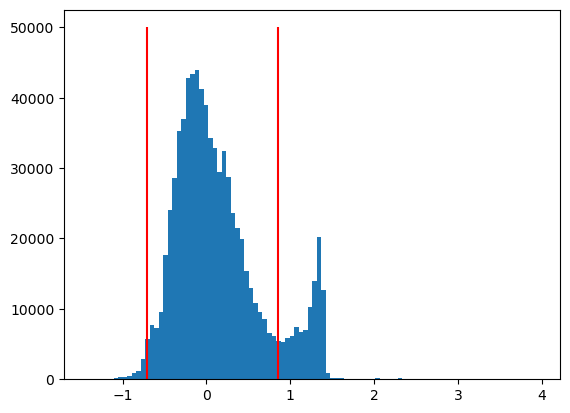

In [52]:
data_processed = data_1_vk4_tiltcorr['baseplane_subtracted'].flatten()
plt.hist(data_processed, bins=100)
p_low, p_high = np.percentile(data_processed, (1, 87))
plt.vlines(p_low, 0, 50000, 'red')
plt.vlines(p_high, 0, 50000, 'red')
plt.show()

**Optical image for reference**

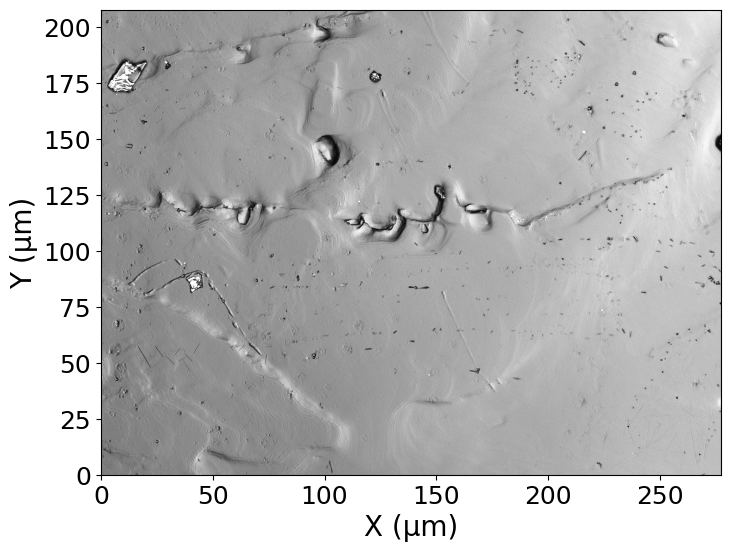

In [258]:
ax = plot_vk4_reflected_light(data_1_vk4)

**Use new clip percentiles determined from histogram\
Clipping lower end necessary because deep holes dominate height bar and small features disappear -> if we have estimates of how deep features/etch pits are cutting away everything deeper is justified right?** 

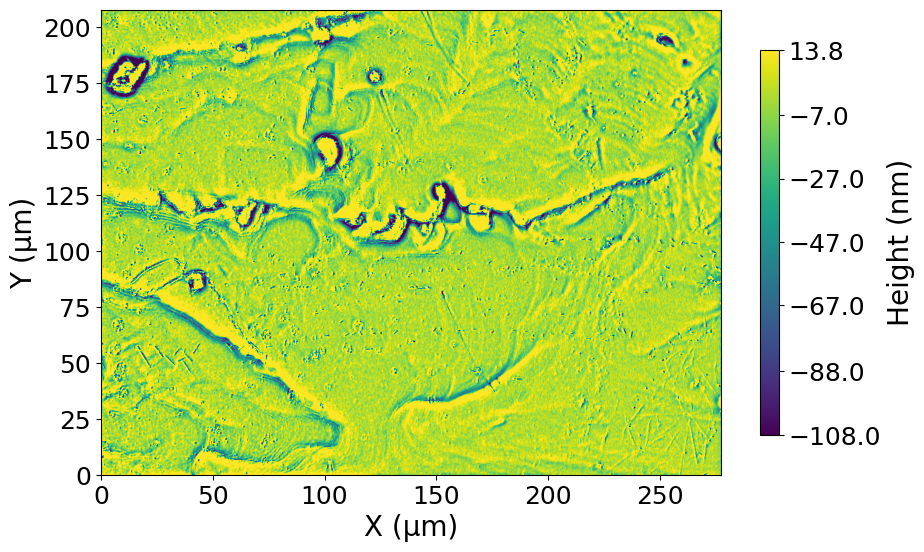

In [103]:
data_1_vk4_enhanced = feature_enhancement_single_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

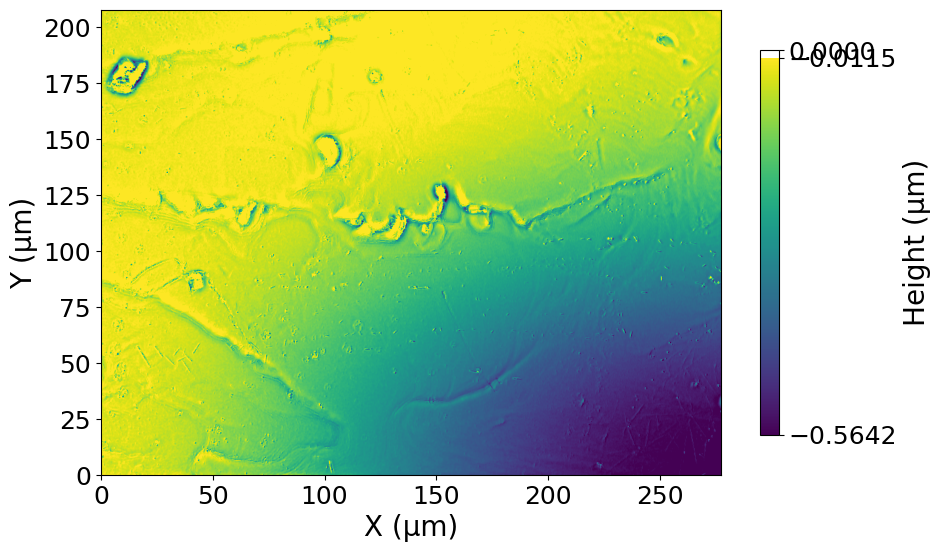

In [110]:
data_1_vk4_enhanced = feature_enhancement_double_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

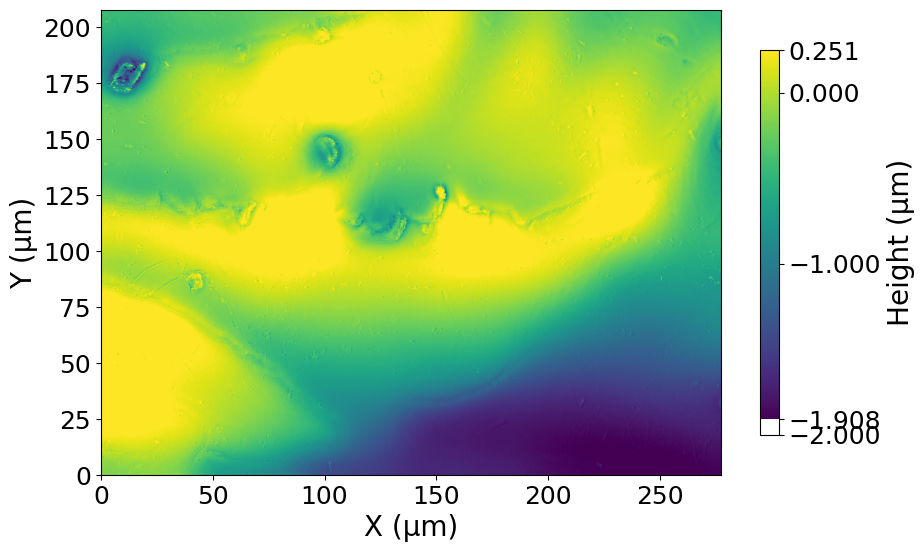

In [108]:
data_1_vk4_enhanced = feature_enhancement_triple_gaussian_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Instead of clipping set height values above and beneath the percentiles to median**

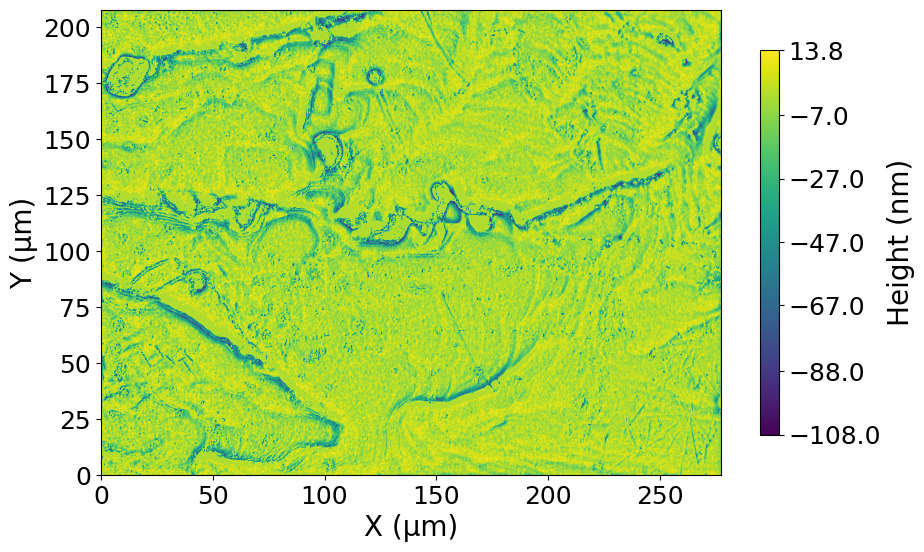

In [113]:
data_1_vk4_enhanced = feature_enhancement_single_gaussian_median_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

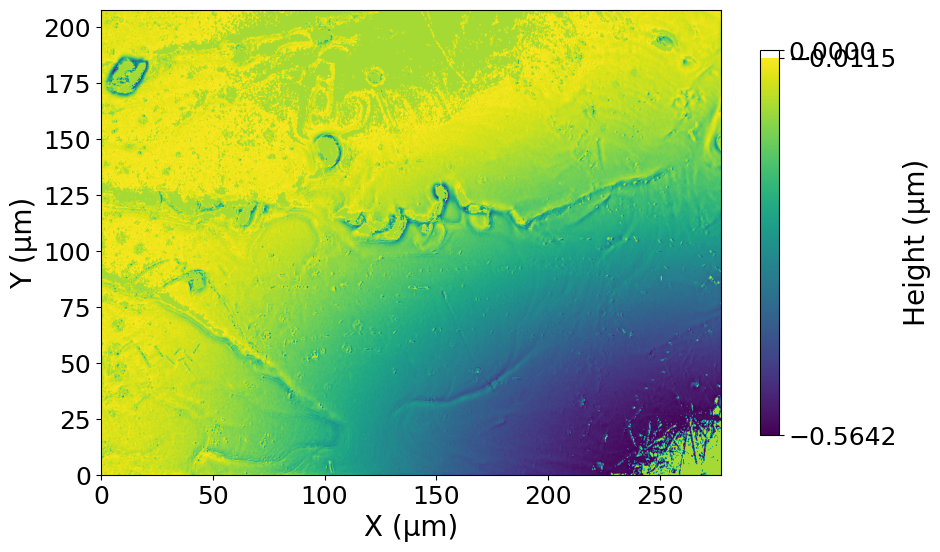

In [114]:
data_1_vk4_enhanced = feature_enhancement_double_gaussian_median_clip(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Single gaussian filter with sigma=5 from now on\
Usolved mystery: why clipping height on both ends makes height range bigger compared to only clipping upper end? (compare with feature_enhancement_single_gaussian_median_clip)**

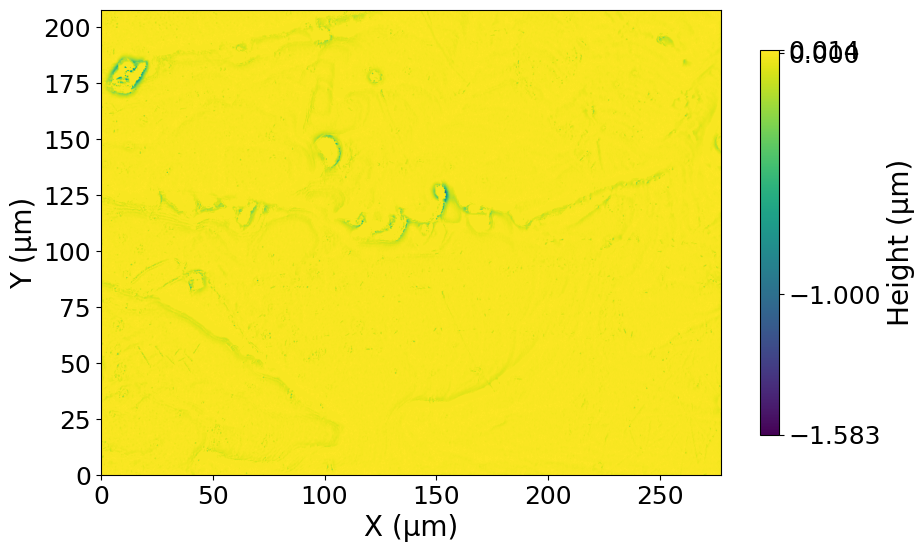

In [115]:
data_1_vk4_enhanced = feature_enhancement_median_clip_high(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**Best result so far imho because small holes are very distinct compared to background\
Setting everything above baseplane (which should be at 0) to 0 should not distort the proportions\
Cutting deep holes that are too deep to be features helps reduce height range\
Trade-off: range too small -> enhances features, but might lose some feature if you start cutting beneath 0; range too big -> features not visible because topography dominates**

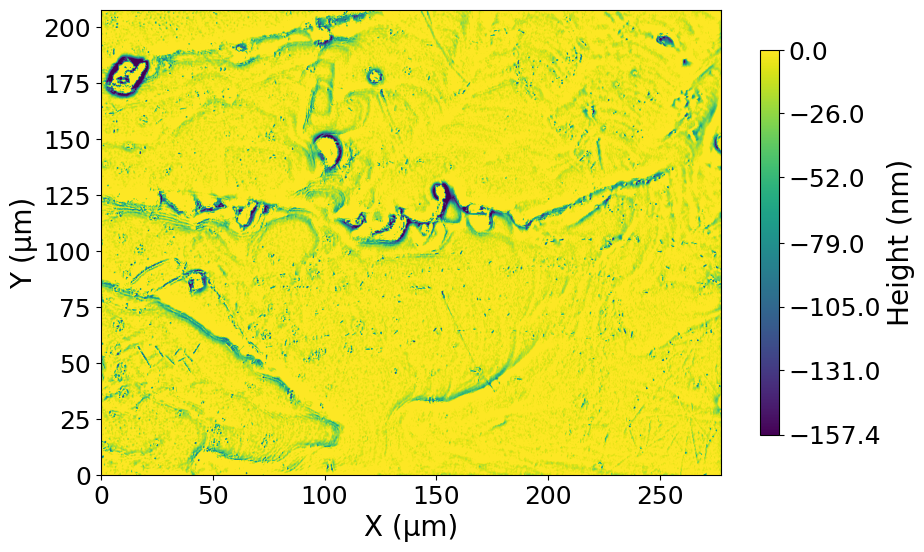

In [141]:
data_1_vk4_enhanced = feature_enhancement_cut_elevations_and_holes(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

**black_tophat from scikit-image, should enhance small dark holes; maybe good for ML but height values are of course not correct anymore**

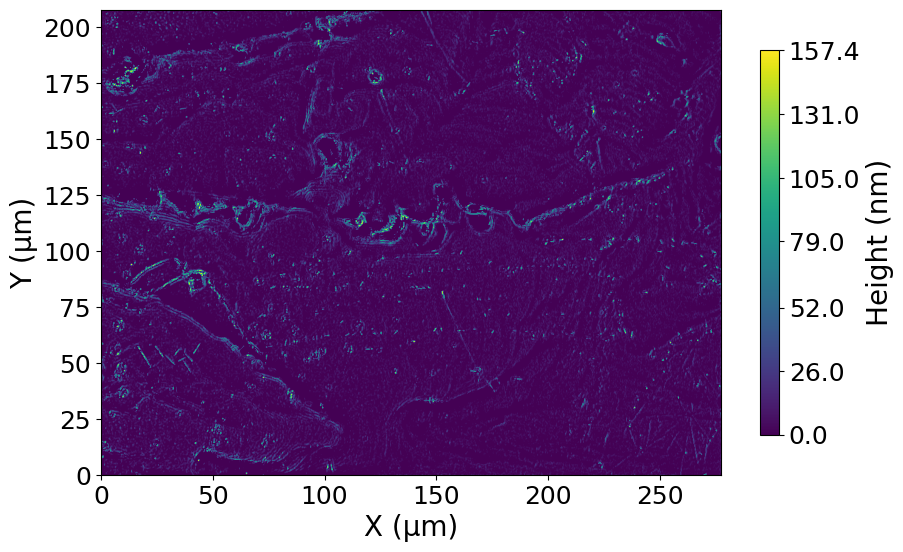

In [122]:
data_1_vk4_enhanced = feature_enhancement_morphological(data_1_vk4_tiltcorr)

ax = plot_vk4_height(data_1_vk4_enhanced, data_type='feature_enhanced')

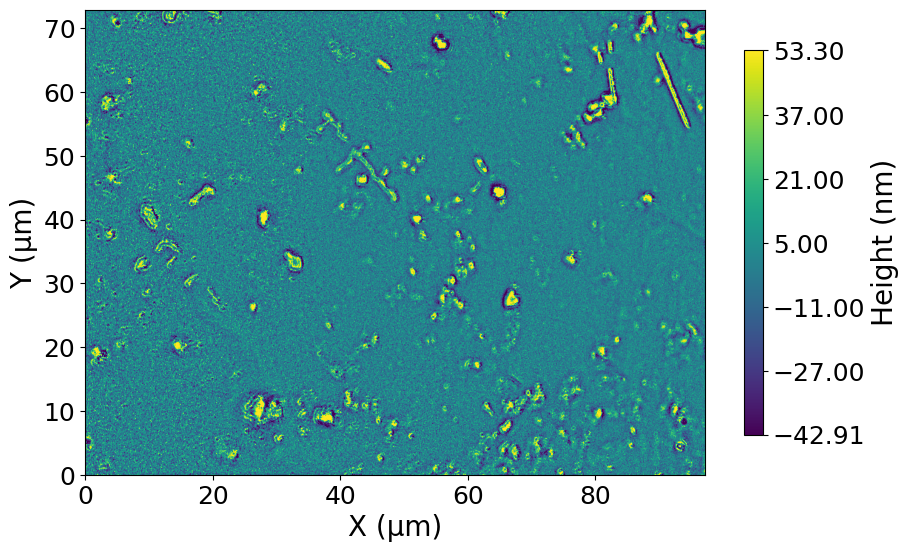

In [166]:
file_name4 = Path("../raw_data_vk/Sample 3 Milan full/Stitched 150x/20260619161302_Y4_X1.vk4")

with open(file_name4, 'rb') as f:
    data_4_vk4 = parse_vk4_file(f)

data_4_vk4_tiltcorr = baseplane_filter(data_4_vk4, 80)
data_4_vk4_enhanced = feature_enhancement_proceedings(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced, data_type='feature_enhanced')

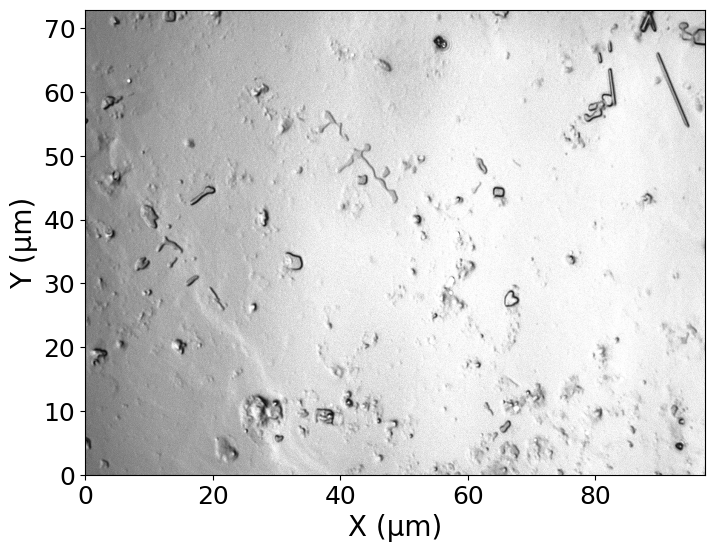

In [167]:
ax = plot_vk4_reflected_light(data_4_vk4)

**Why is there almost always an elevated area next to hole?**

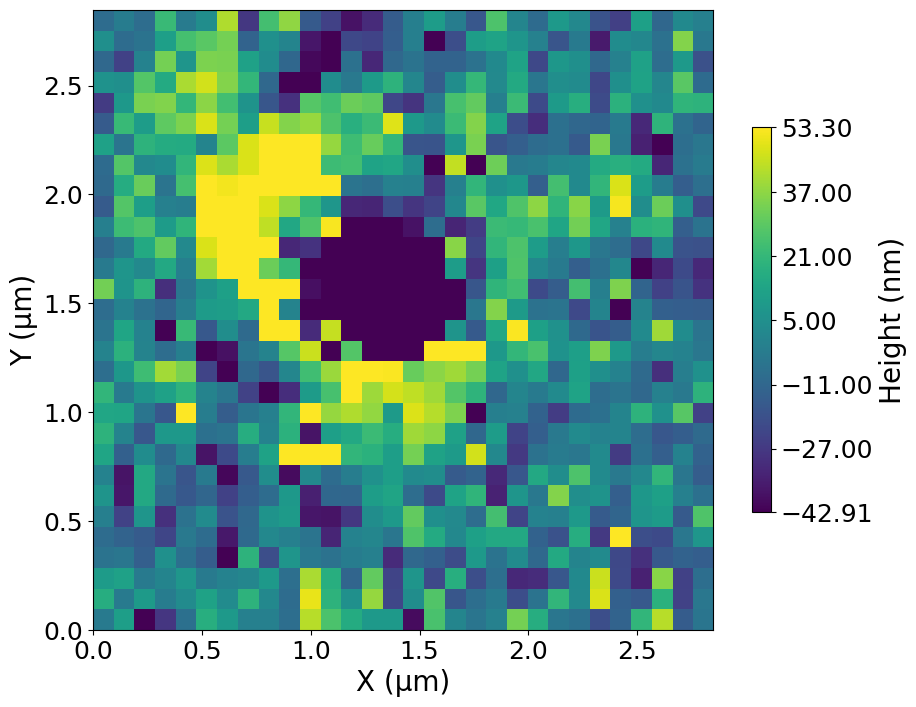

In [168]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')
#plt.savefig('small feature.jpeg')
#plt.plot()

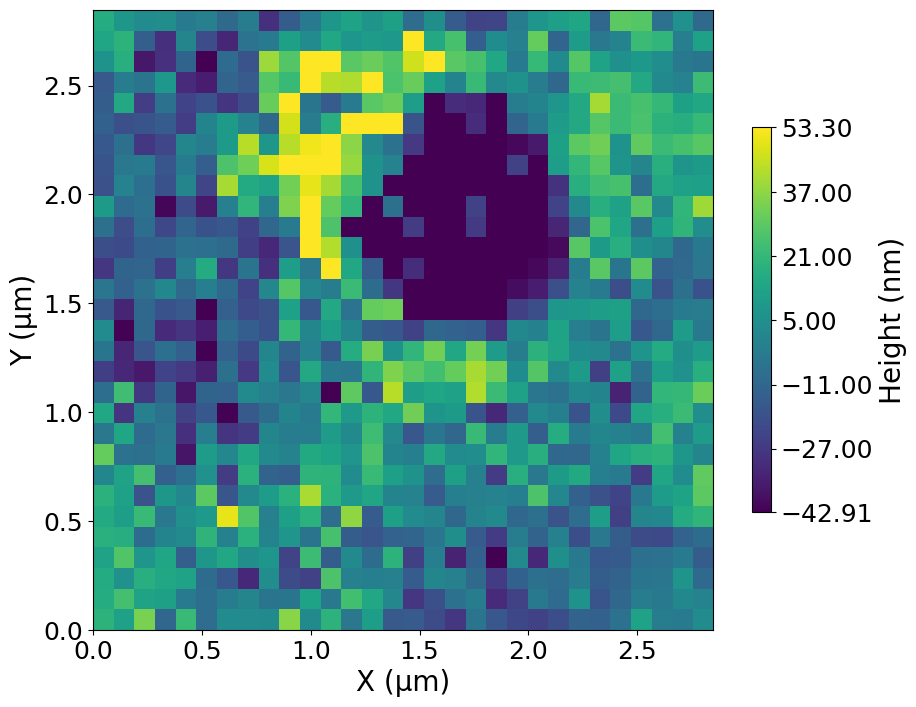

In [ ]:
cropped = crop_Vk4File_map(data_4_vk4_enhanced, x0=970, x1=1000, y0=670, y1=700)


ax = plot_vk4_height(cropped, data_type='feature_enhanced')

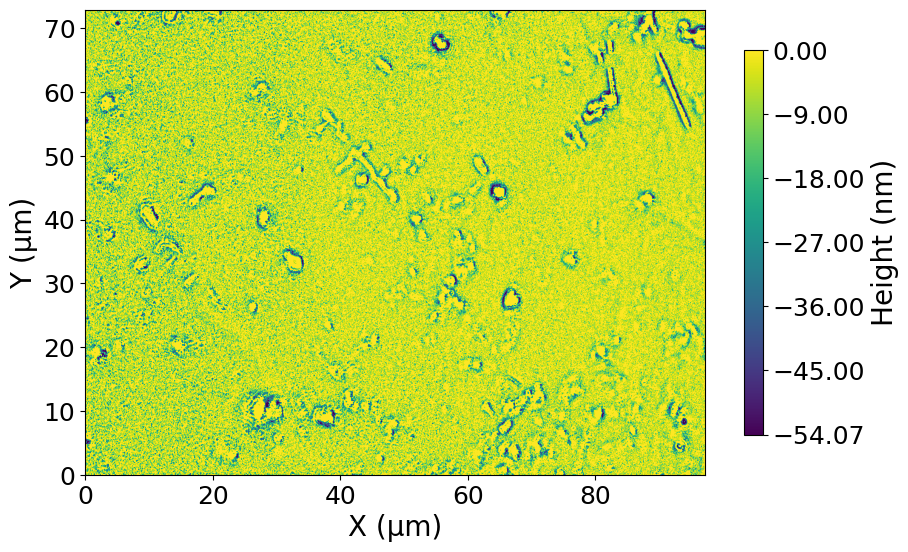

In [155]:
data_4_vk4_enhanced_2 = feature_enhancement_cut_elevations_and_holes(data_4_vk4_tiltcorr)

ax = plot_vk4_height(data_4_vk4_enhanced_2, data_type='feature_enhanced')

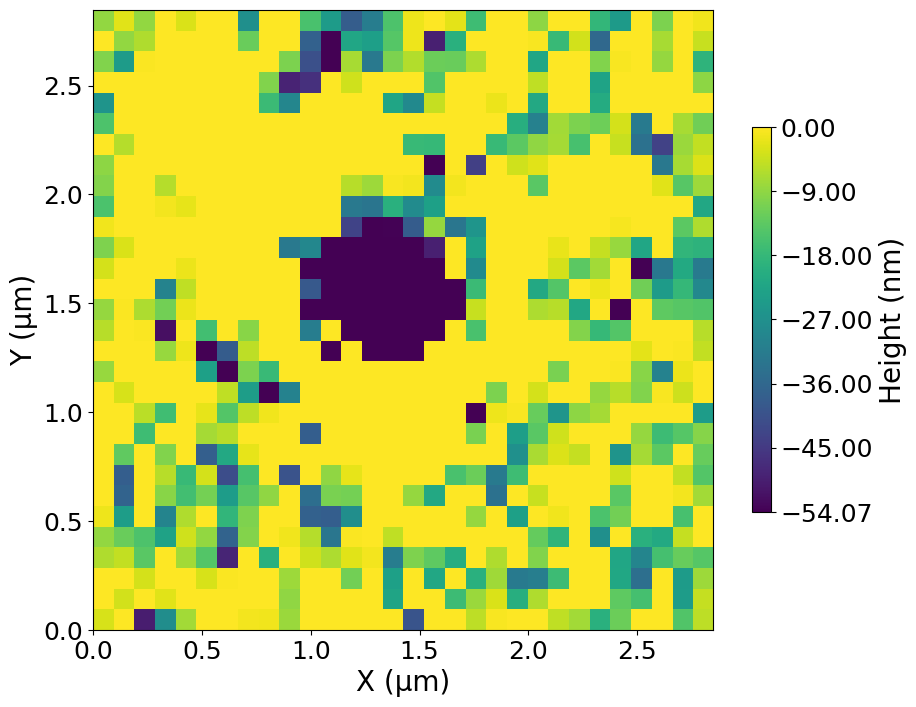

In [157]:
cropped_2 = crop_Vk4File_map(data_4_vk4_enhanced_2, x0=40, x1=70, y0=10, y1=40)


ax = plot_vk4_height(cropped_2, data_type='feature_enhanced')

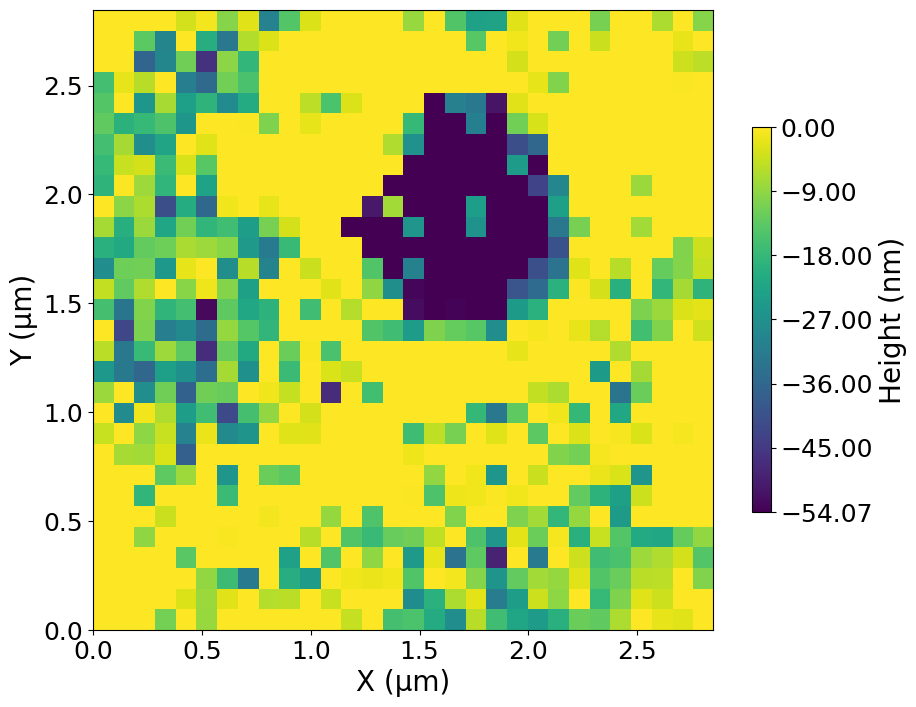

In [170]:
cropped_2 = crop_Vk4File_map(data_4_vk4_enhanced_2, x0=970, x1=1000, y0=670, y1=700)


ax = plot_vk4_height(cropped_2, data_type='feature_enhanced')